In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from pathlib import Path

## Teste de função nativa do librosa

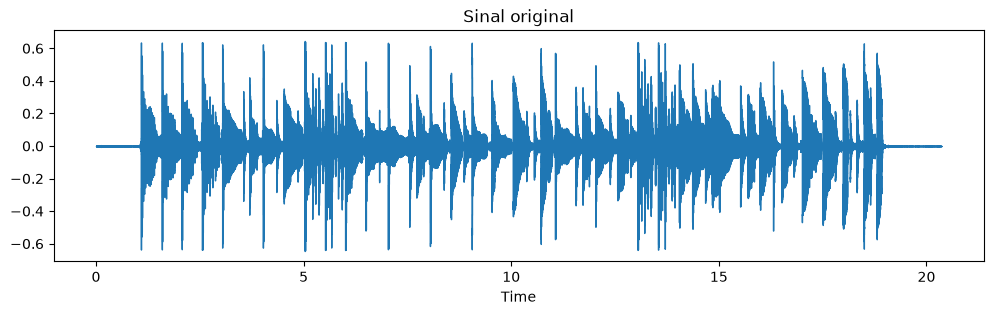

Sample rate: 44100


In [2]:
gardenia, sr = librosa.load("../audio_samples/gardenia.wav", sr=None, mono=True)
plt.figure(figsize=(12, 3))
librosa.display.waveshow(gardenia, sr=sr)
plt.title("Sinal original")
plt.show()
print("Sample rate:", sr)

In [3]:
f0, voiced_flag, voiced_probs = librosa.pyin(
    gardenia, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C7')
)
print(f"Pitch estimado: {np.nanmean(f0):.1f} Hz")

Pitch estimado: 91.9 Hz


In [4]:
semitones = -5  # transpor 5 semitons acima
y_shifted = librosa.effects.pitch_shift(gardenia, sr=sr, n_steps=semitones)
sf.write("../audio_samples/gardenia_down_5.wav", y_shifted, sr)

## Comparando som do Mi natural com "sintetico"
Utilizando função nativa do librosa

In [5]:
# Configurações
INPUT_DIR = Path("../audio_samples")
OUTPUT_DIR = Path("../audio_samples_shifted")
SEMITONES = -5  # A -> E (5 semitons abaixo)

OUTPUT_DIR.mkdir(exist_ok=True)

# Filtrar apenas os arquivos do grupo A
a_files = [f for f in INPUT_DIR.glob("A_*.wav")]

print(f"Encontrados {len(a_files)} arquivos do grupo A:\n")


Encontrados 4 arquivos do grupo A:



Processando: A_natural.wav ...


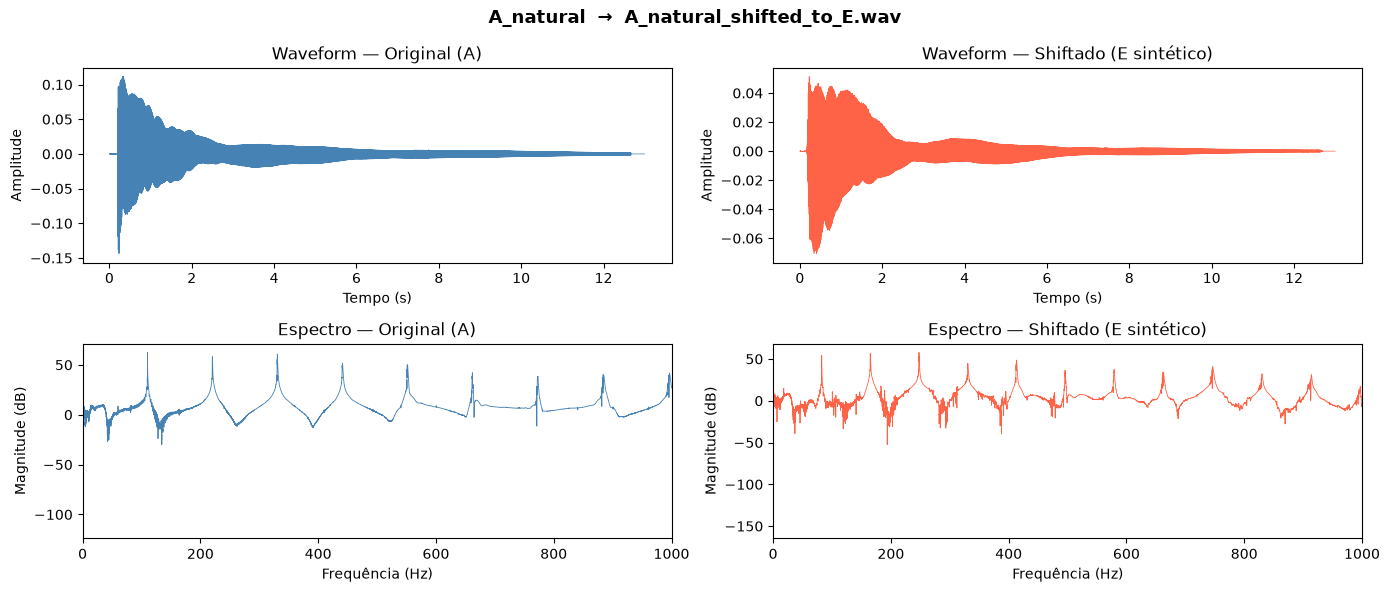

Processando: A_natural_bleed.wav ...


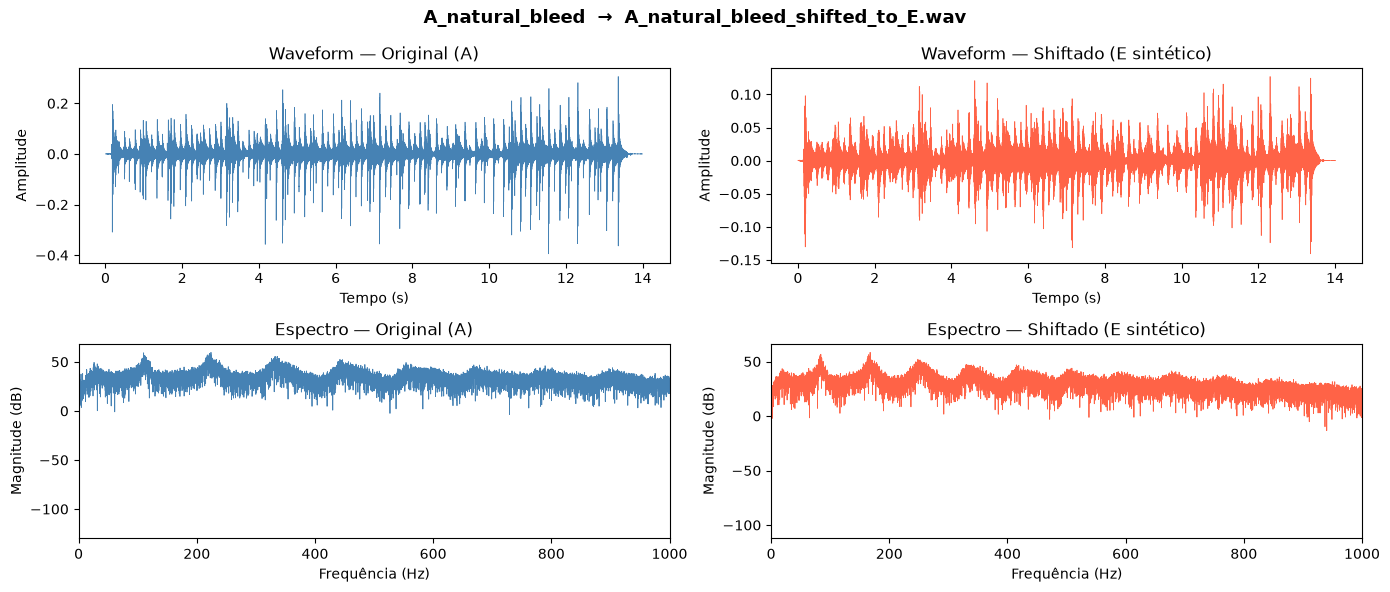

Processando: A_natural_pedal_open.wav ...


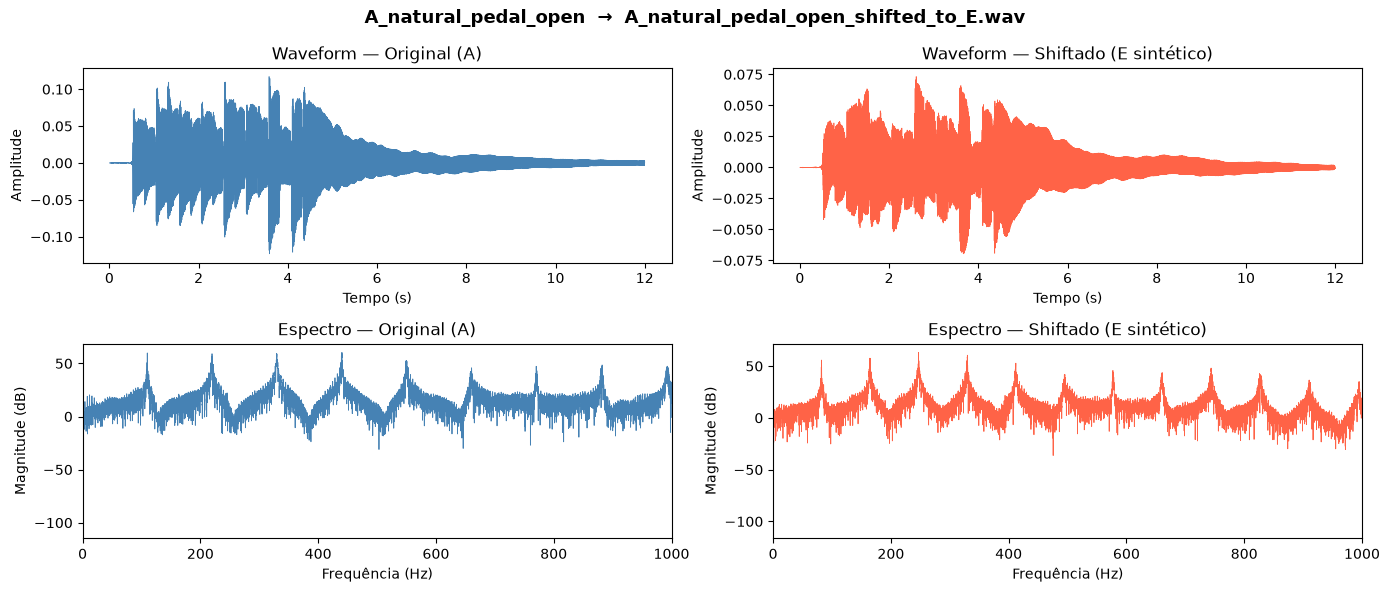

Processando: A_natural_pedal_pm.wav ...


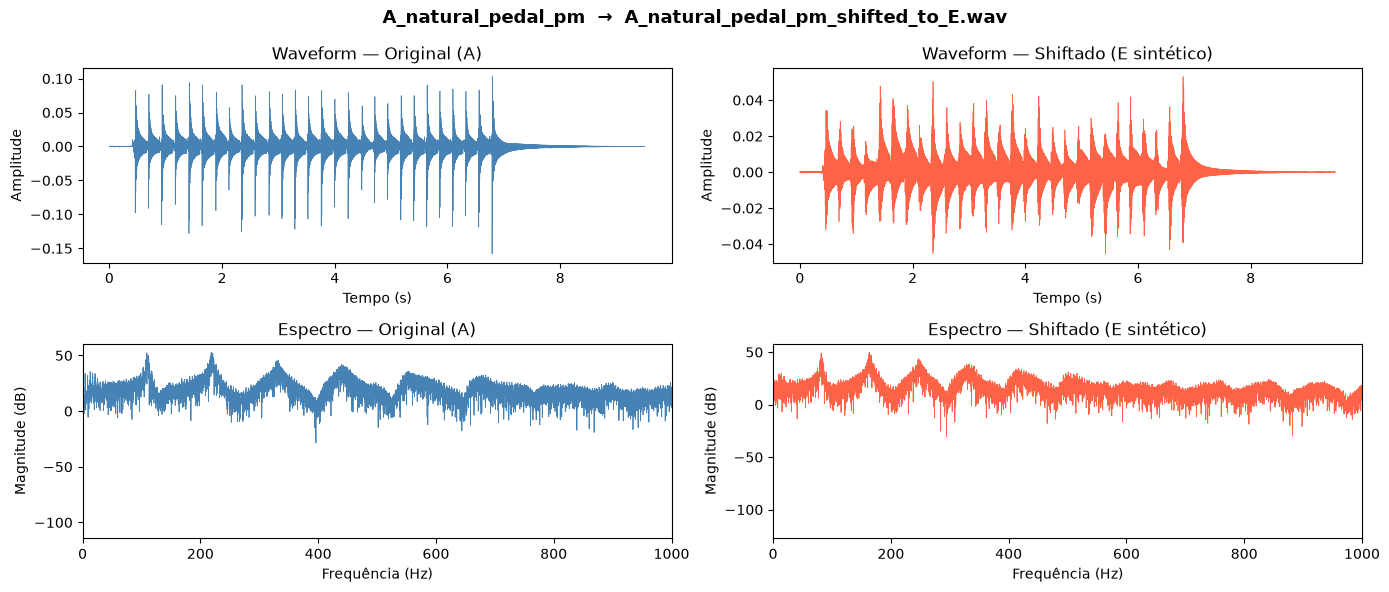


Concluído.


In [8]:
for file in a_files:
    print(f"Processando: {file.name} ...")

    y, sr = librosa.load(file, sr=None, mono=True)
    y_shifted = librosa.effects.pitch_shift(y, sr=sr, n_steps=SEMITONES)

    # Salvar áudio shiftado
    out_name = file.stem + "_shifted_to_E.wav"
    sf.write(OUTPUT_DIR / out_name, y_shifted, sr)

    # --- Figura com 4 painéis: waveform + espectro para original e shiftado ---
    fig, axes = plt.subplots(2, 2, figsize=(14, 6))
    fig.suptitle(f"{file.stem}  →  {out_name}", fontsize=13, fontweight="bold")

    time_orig = np.linspace(0, len(y) / sr, len(y))
    time_shift = np.linspace(0, len(y_shifted) / sr, len(y_shifted))

    # Waveform original
    axes[0, 0].plot(time_orig, y, color="steelblue", linewidth=0.5)
    axes[0, 0].set_title("Waveform — Original (A)")
    axes[0, 0].set_xlabel("Tempo (s)")
    axes[0, 0].set_ylabel("Amplitude")

    # Waveform shiftado
    axes[0, 1].plot(time_shift, y_shifted, color="tomato", linewidth=0.5)
    axes[0, 1].set_title("Waveform — Shiftado (E sintético)")
    axes[0, 1].set_xlabel("Tempo (s)")
    axes[0, 1].set_ylabel("Amplitude")

    # Espectro de magnitude (FFT) original
    N = len(y)
    freqs = np.fft.rfftfreq(N, d=1/sr)
    mag = np.abs(np.fft.rfft(y))
    mag_db = 20 * np.log10(mag + 1e-9)
    axes[1, 0].plot(freqs, mag_db, color="steelblue", linewidth=0.6)
    axes[1, 0].set_title("Espectro — Original (A)")
    axes[1, 0].set_xlabel("Frequência (Hz)")
    axes[1, 0].set_ylabel("Magnitude (dB)")
    axes[1, 0].set_xlim(0, 1000)

    # Espectro de magnitude (FFT) shiftado
    N2 = len(y_shifted)
    freqs2 = np.fft.rfftfreq(N2, d=1/sr)
    mag2 = np.abs(np.fft.rfft(y_shifted))
    mag_db2 = 20 * np.log10(mag2 + 1e-9)
    axes[1, 1].plot(freqs2, mag_db2, color="tomato", linewidth=0.6)
    axes[1, 1].set_title("Espectro — Shiftado (E sintético)")
    axes[1, 1].set_xlabel("Frequência (Hz)")
    axes[1, 1].set_ylabel("Magnitude (dB)")
    axes[1, 1].set_xlim(0, 1000)

    plt.tight_layout()
    plt.show()

print("\nConcluído.")

Arquivo                             RMS     Pico    Pico Transiente
--------------------------------------------------------------------
A_natural | A original           0.0108   0.1439             0.0003
A_natural | E natural            0.0127   0.1371             0.0002
A_natural | E sintético          0.0071   0.0707             0.0004

bleed | A original               0.0263   0.3947             0.0006
bleed | E natural                0.0271   0.3685             0.0004
bleed | E sintético              0.0174   0.1408             0.0008

pedal_open | A original          0.0160   0.1232             0.0003
pedal_open | E natural           0.0269   0.1567             0.0017
pedal_open | E sintético         0.0126   0.0732             0.0002

pedal_pm | A original            0.0097   0.1580             0.0006
pedal_pm | E natural             0.0234   0.2423             0.0022
pedal_pm | E sintético           0.0066   0.0531             0.0005



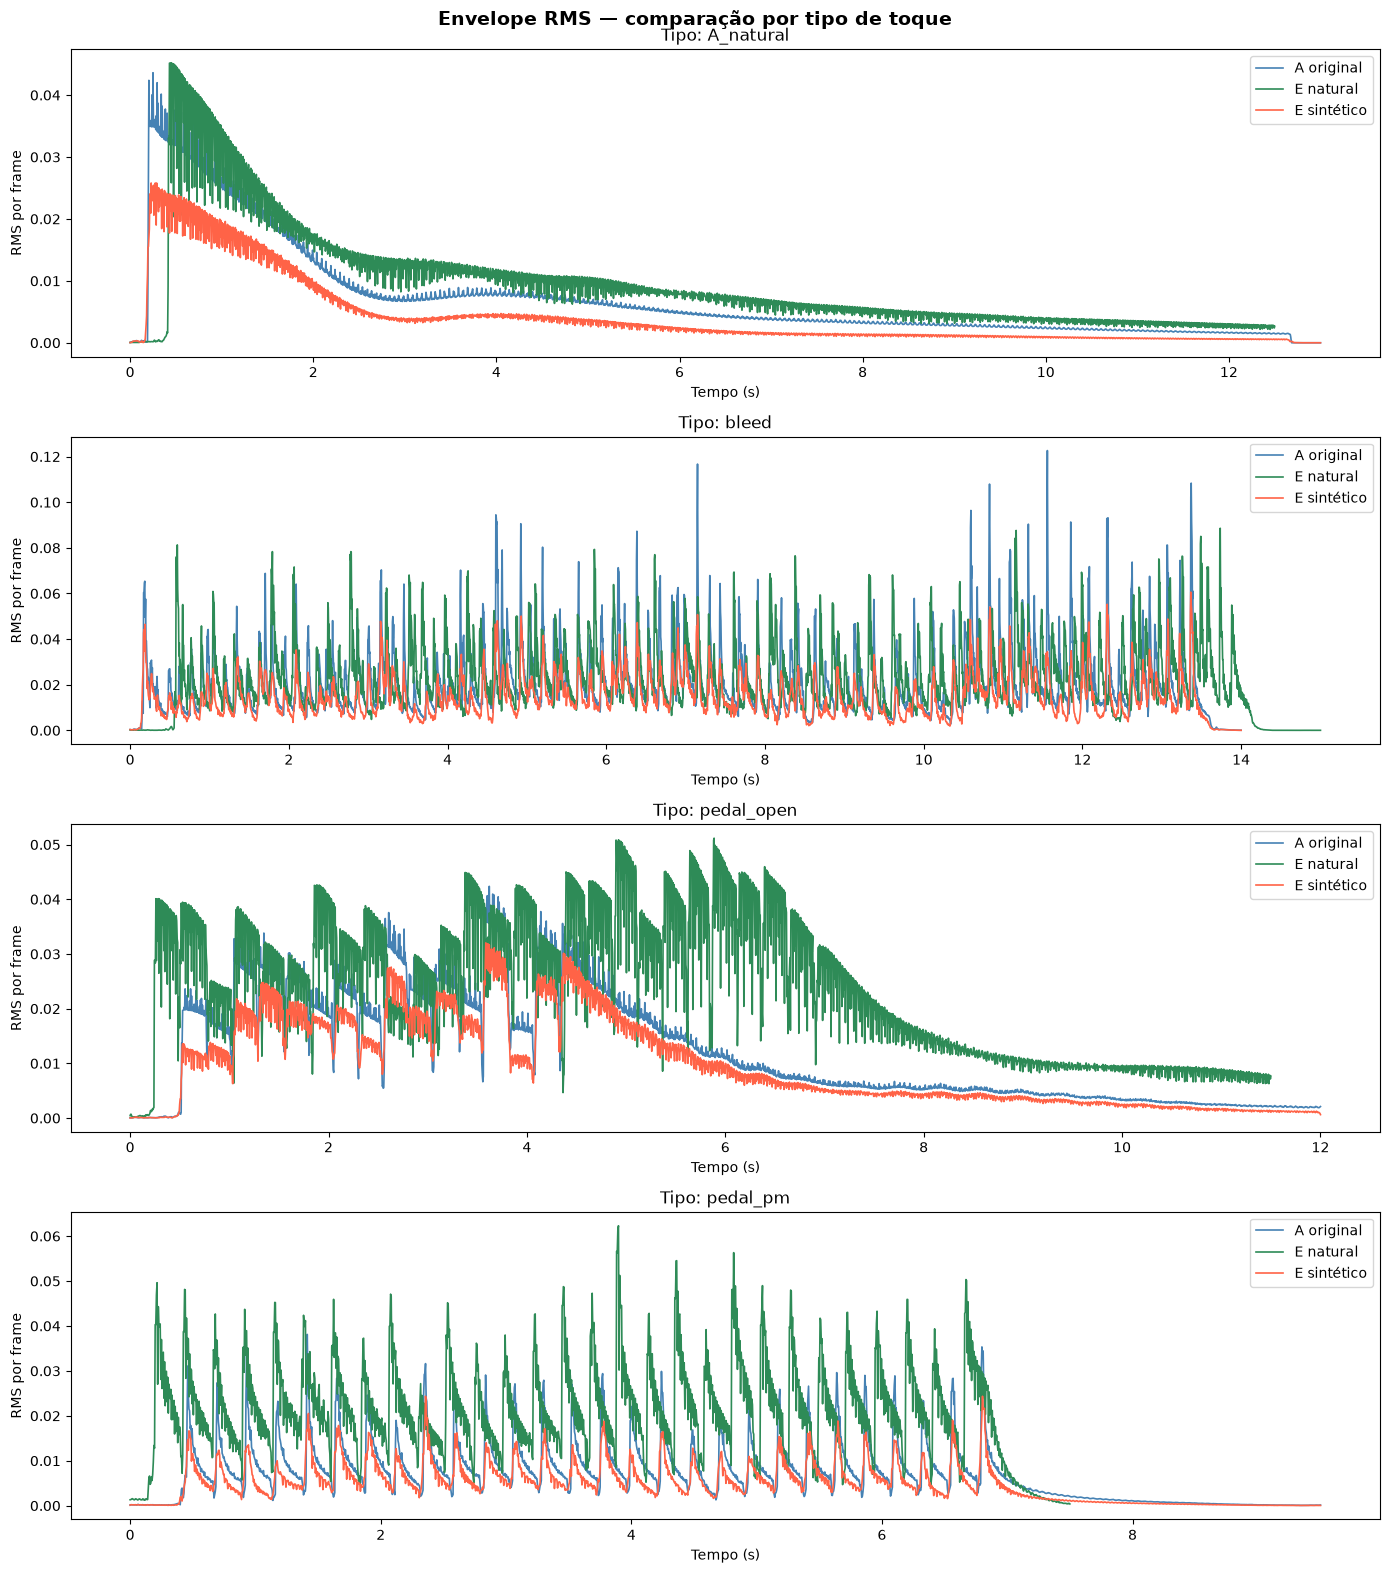

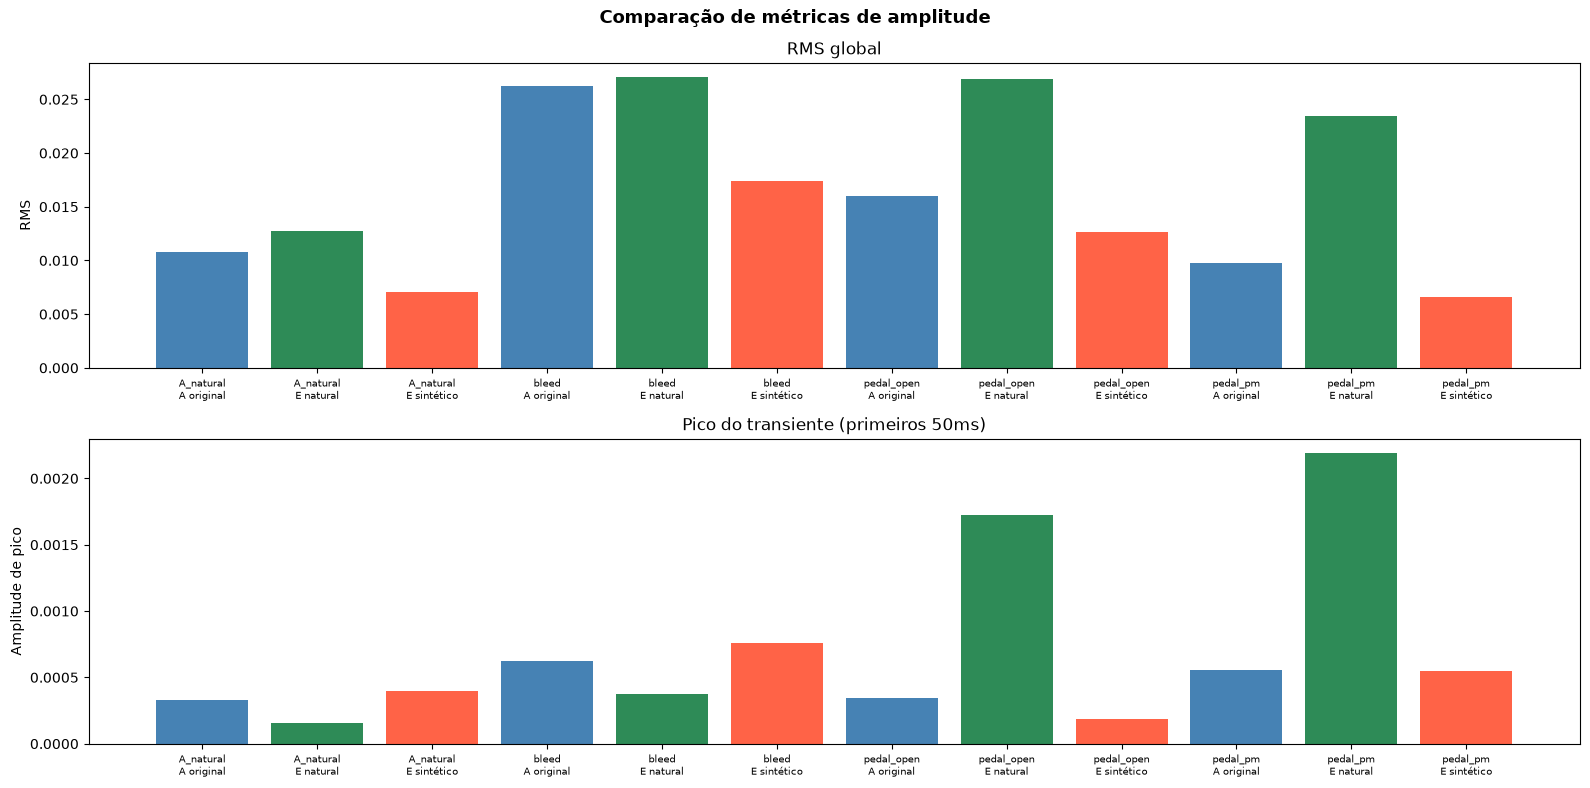

In [ ]:
INPUT_DIR  = Path("../audio_samples")
OUTPUT_DIR = Path("../audio_samples_shifted")

# Pares: (A original, E natural equivalente, E sintético)
pairs = [
    ("A_natural.wav",          "E_natural.wav",          "A_natural_shifted_to_E.wav"),
    ("A_natural_bleed.wav",    "E_natural_bleed.wav",    "A_natural_bleed_shifted_to_E.wav"),
    ("A_natural_pedal_open.wav","E_natural_pedal_open.wav","A_natural_pedal_open_shifted_to_E.wav"),
    ("A_natural_pedal_pm.wav", "E_natural_pedal_pm.wav", "A_natural_pedal_pm_shifted_to_E.wav"),
]

# --- Funções de métricas ---

def rms(y):
    return np.sqrt(np.mean(y**2))

def peak(y):
    return np.max(np.abs(y))

def rms_envelope(y, sr, frame_sec=0.01):
    """RMS frame a frame — mostra como a energia evolui no tempo."""
    frame_len = int(frame_sec * sr)
    frames = librosa.util.frame(y, frame_length=frame_len, hop_length=frame_len//2)
    return np.sqrt(np.mean(frames**2, axis=0))

def transient_peak(y, sr, attack_sec=0.05):
    """Pico máximo nos primeiros 'attack_sec' segundos — proxy do transiente."""
    attack_samples = int(attack_sec * sr)
    return np.max(np.abs(y[:attack_samples]))

# --- Loop principal ---

print(f"{'Arquivo':<30} {'RMS':>8} {'Pico':>8} {'Pico Transiente':>18}")
print("-" * 68)

fig, axes = plt.subplots(len(pairs), 1, figsize=(14, 4 * len(pairs)))
fig.suptitle("Envelope RMS — comparação por tipo de toque", fontsize=14, fontweight="bold")

results = []

for i, (a_file, e_nat_file, e_syn_file) in enumerate(pairs):
    y_a,     sr = librosa.load(INPUT_DIR  / a_file,     sr=None, mono=True)
    y_e_nat, _  = librosa.load(INPUT_DIR  / e_nat_file, sr=None, mono=True)
    y_e_syn, _  = librosa.load(OUTPUT_DIR / e_syn_file, sr=None, mono=True)

    label = a_file.replace("A_natural_", "").replace(".wav", "") or "natural"

    for name, y in [("A original", y_a), ("E natural", y_e_nat), ("E sintético", y_e_syn)]:
        r  = rms(y)
        p  = peak(y)
        tp = transient_peak(y, sr)
        results.append({"label": label, "name": name, "rms": r, "peak": p, "transient_peak": tp})
        print(f"{label+' | '+name:<30} {r:>8.4f} {p:>8.4f} {tp:>18.4f}")

    print()

    # Envelope RMS no tempo
    ax = axes[i]
    for name, y, color in [
        ("A original",  y_a,     "steelblue"),
        ("E natural",   y_e_nat, "seagreen"),
        ("E sintético", y_e_syn, "tomato"),
    ]:
        env = rms_envelope(y, sr)
        t   = np.linspace(0, len(y)/sr, len(env))
        ax.plot(t, env, label=name, color=color, linewidth=1.2)

    ax.set_title(f"Tipo: {label}")
    ax.set_xlabel("Tempo (s)")
    ax.set_ylabel("RMS por frame")
    ax.legend()

plt.tight_layout()
plt.show()

# --- Gráfico de barras comparativo ---
labels_plot = [r["label"] + "\n" + r["name"] for r in results]
rms_vals    = [r["rms"]            for r in results]
tp_vals     = [r["transient_peak"] for r in results]

x = np.arange(len(results))
fig2, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8))
fig2.suptitle("Comparação de métricas de amplitude", fontsize=13, fontweight="bold")

colors = ["steelblue", "seagreen", "tomato"] * len(pairs)

ax1.bar(x, rms_vals, color=colors)
ax1.set_xticks(x); ax1.set_xticklabels(labels_plot, fontsize=7)
ax1.set_ylabel("RMS"); ax1.set_title("RMS global")

ax2.bar(x, tp_vals, color=colors)
ax2.set_xticks(x); ax2.set_xticklabels(labels_plot, fontsize=7)
ax2.set_ylabel("Amplitude de pico"); ax2.set_title("Pico do transiente (primeiros 50ms)")

plt.tight_layout()
plt.show()
